# 01 — Exploratory Data Analysis

## Project: UCI Bank Marketing — Term Deposit Subscription

This notebook examines the UCI Bank Marketing dataset before model development.

**Business question:** Can information available before a marketing call help identify customers who are more likely to subscribe to a term deposit?

**Prediction-time boundary:** The primary use case is a prediction made *before* the current campaign call. `duration` is recorded during/after the call, so it is useful for retrospective exploration but must not be used as a predictor in the pre-call model.

### Notebook roadmap
1. Load the data and inspect its structure and quality.
2. Examine the target distribution and class imbalance.
3. Explore numerical variables.
4. Compare subscription rates across categorical features.
5. Investigate previous-contact history and current campaign frequency.
6. Document prediction-time leakage and summarize findings.

**Dataset:** `bank-full.csv`, read with `sep=';'`. If the file is missing, run `python src/download_data.py` from the project root.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Support execution from either the project root or notebooks/ directory.
candidate_paths = [
    Path("../data/raw/bank-full.csv"),
    Path("data/raw/bank-full.csv"),
]
data_path = next((path for path in candidate_paths if path.exists()), None)

if data_path is None:
    raise FileNotFoundError(
        "Could not find data/raw/bank-full.csv. "
        "Run `python src/download_data.py` from the project root."
    )

# The UCI source file uses semicolons as field separators.
df = pd.read_csv(data_path, sep=";")

print(f"Loaded dataset: {data_path}")
print(f"Dataset shape: {df.shape[0]:,} rows × {df.shape[1]} columns")

Loaded dataset: ../data/raw/bank-full.csv
Dataset shape: 45,211 rows × 17 columns


## 1. Dataset structure and data quality

Review column types, descriptive statistics, duplicate records, and missing values. The source also uses the literal category `unknown` in some categorical fields. This is not the same as a pandas null value, so quantify it separately.

In [2]:
# Inspect column types and non-null counts.
df.info()

# Summarize numeric and categorical columns.
display(df.describe(include="all").T)

# Count exact duplicate records and true missing values.
print(f"Exact duplicate rows: {df.duplicated().sum():,}")
print("True missing values by column:")
display(df.isna().sum().sort_values(ascending=False))

# Count explicit 'unknown' values in categorical columns.
categorical_columns = df.select_dtypes(include=["object", "str"]).columns.tolist()
unknown_counts = (
    df[categorical_columns].eq("unknown").sum().sort_values(ascending=False)
)
print("Explicit 'unknown' values by categorical column:")
display(unknown_counts[unknown_counts > 0])

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 5.9 MB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,45211.0,NaN,NaN,NaN,40.93621,10.618762,18.0,33.0,39.0,48.0,95.0
job,45211,12,blue-collar,9732,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital,45211,3,married,27214,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education,45211,4,secondary,23202,NaN,NaN,NaN,NaN,NaN,NaN,NaN
default,45211,2,no,44396,NaN,NaN,NaN,NaN,NaN,NaN,NaN
balance,45211.0,NaN,NaN,NaN,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
housing,45211,2,yes,25130,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan,45211,2,no,37967,NaN,NaN,NaN,NaN,NaN,NaN,NaN
contact,45211,3,cellular,29285,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day,45211.0,NaN,NaN,NaN,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0


Exact duplicate rows: 0
True missing values by column:


age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

Explicit 'unknown' values by categorical column:


poutcome     36959
contact      13020
education     1857
job            288
dtype: int64

### Data quality notes

- **True missing values** are values recognized by pandas as null.
- **`unknown` category values** are recorded values in the source data and may indicate unavailable or unrecorded information.

For this initial analysis, we will retain `unknown` as an explicit category, and decide how to handle it during modeling based on validation results rather than assuming it is equivalent to a null.

## 2. Target distribution and class imbalance

The target column `y` indicates whether a customer subscribed to a term deposit (`yes` or `no`). Quantify both the number and percentage in each class. Accuracy alone can be misleading when one class is much more common than the other.

Target class distribution:


,customers,percentage
y,,
no,39922,88.3
yes,5289,11.7


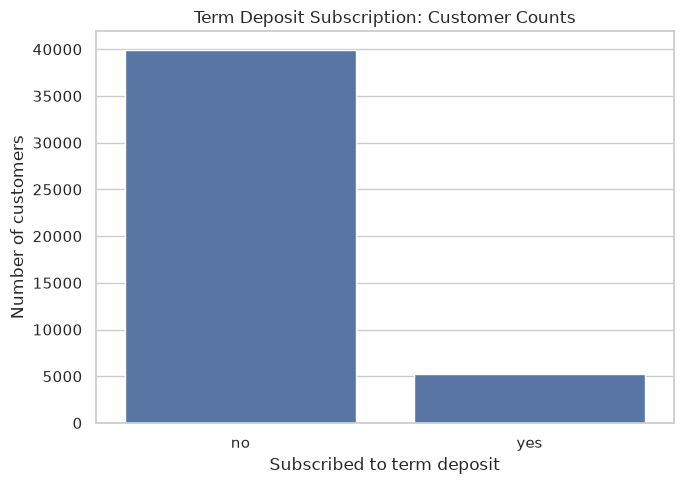

In [3]:
# Summarize target counts and percentages.
target_counts = df["y"].value_counts()
target_percentages = df["y"].value_counts(normalize=True) * 100
target_summary = pd.DataFrame({
    "customers": target_counts,
    "percentage": target_percentages.round(2),
})

print("Target class distribution:")
display(target_summary)

# Visualize the imbalance between non-subscribers and subscribers.
plt.figure(figsize=(7, 5))
ax = sns.countplot(data=df, x="y", order=["no", "yes"])
ax.set_title("Term Deposit Subscription: Customer Counts")
ax.set_xlabel("Subscribed to term deposit")
ax.set_ylabel("Number of customers")
plt.tight_layout()
plt.show()

### Interpretation

Record the positive-class rate (`yes`) and compare it with the negative-class rate (`no`). Use this distribution as baseline context for model evaluation. Accuracy alone will not be an adequate performance measure for this imbalanced target.

## 3. Numerical feature distributions

Inspect numerical variables for skewness, concentration, and potential extreme values. An extreme value is not automatically an error and should not be removed without understanding its meaning.

`duration` is included for exploration only. It will be excluded from the primary pre-call prediction model.

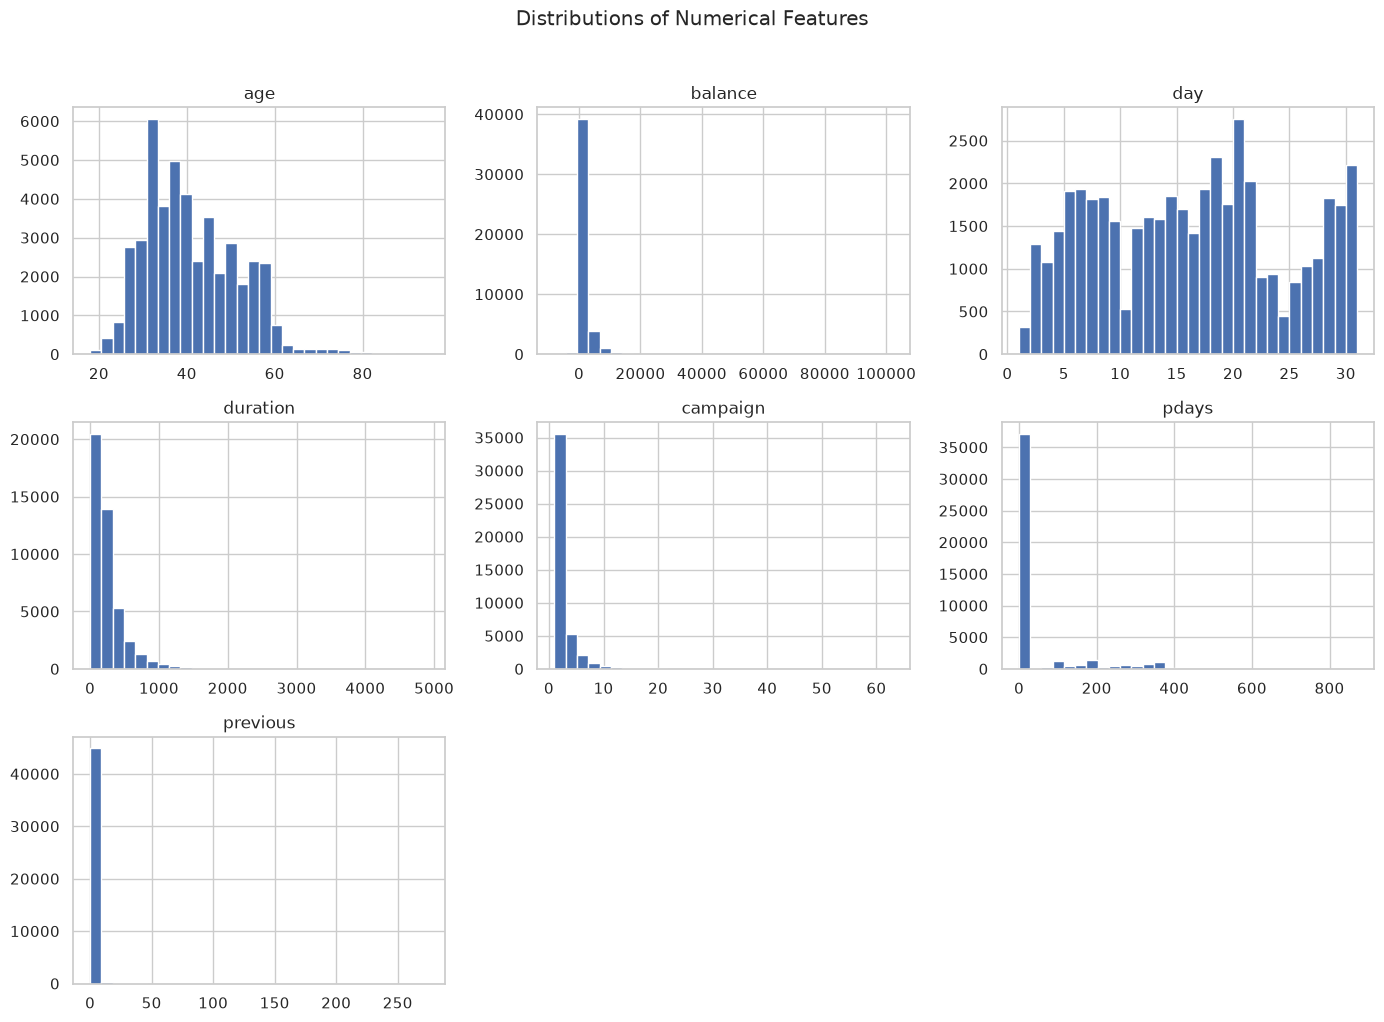

In [4]:
# Identify numerical columns and plot their distributions.
numeric_columns = df.select_dtypes(include="number").columns.tolist()
df[numeric_columns].hist(figsize=(14, 10), bins=30, edgecolor="white")
plt.suptitle("Distributions of Numerical Features", y=1.02)
plt.tight_layout()
plt.show()

### Numerical summaries by subscription outcome

Compare means, medians, and standard deviations across the two target classes. Differences in means can be influenced by skewness and extreme observations, so consider medians and distribution plots as well.

In [5]:
# Compare numerical feature summaries for non-subscribers and subscribers.
numeric_summary = (
    df.groupby("y")[numeric_columns]
      .agg(["mean", "median", "std"])
      .round(2)
)
print("Numerical feature summaries grouped by subscription outcome:")
display(numeric_summary.T)

Numerical feature summaries grouped by subscription outcome:


y                     no      yes
age      mean      40.84    41.67
         median    39.00    38.00
         std       10.17    13.50
balance  mean    1303.71  1804.27
         median   417.00   733.00
         std     2974.20  3501.10
day      mean      15.89    15.16
         median    16.00    15.00
         std        8.29     8.50
duration mean     221.18   537.29
         median   164.00   426.00
         std      207.38   392.53
campaign mean       2.85     2.14
         median     2.00     2.00
         std        3.21     1.92
pdays    mean      36.42    68.70
         median    -1.00    -1.00
         std       96.76   118.82
previous mean       0.50     1.17
         median     0.00     0.00
         std        2.26     2.55

### Boxplots by subscription outcome

These boxplots compare numerical distributions across target classes. Highly skewed variables can compress most observations near the bottom of a plot; use the descriptive statistics and skewness table alongside them.

`pdays` requires special care: `-1` means the customer was not previously contacted, not a number of elapsed days.

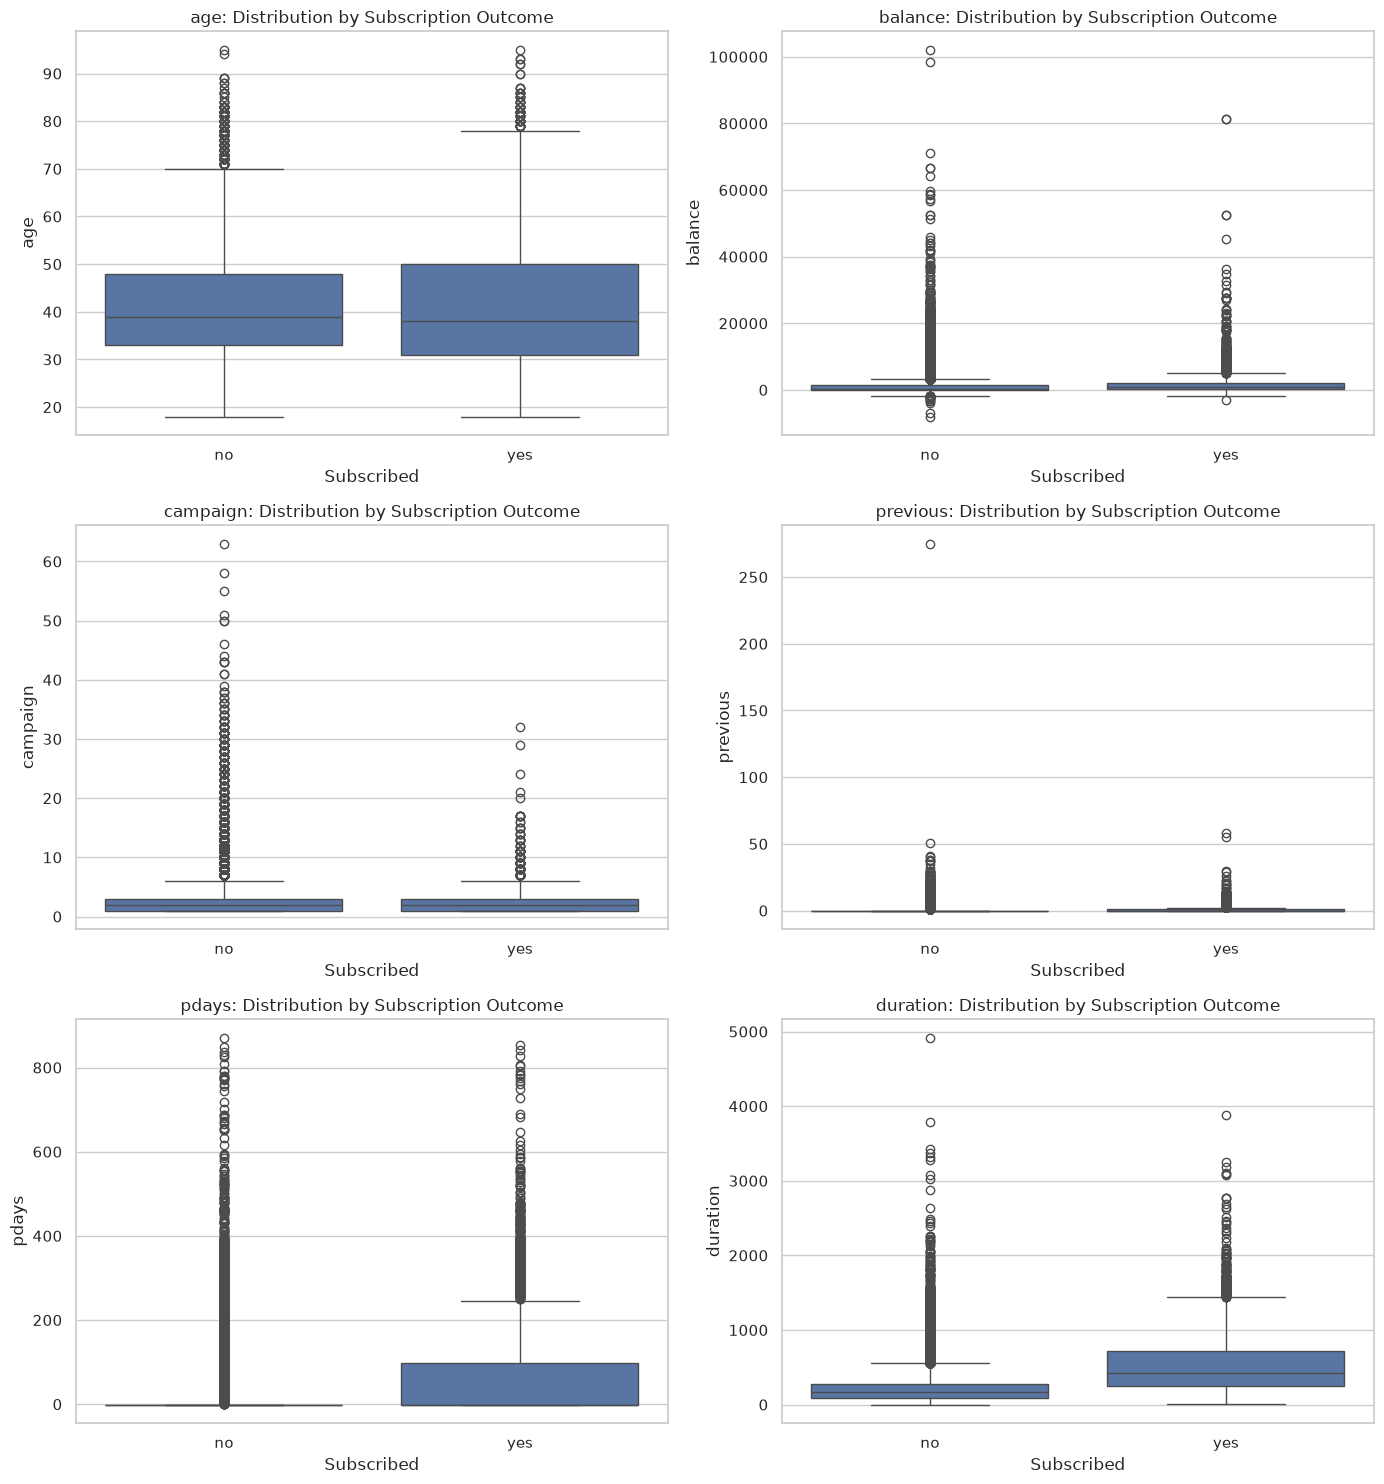

In [6]:
# Compare numerical feature distributions across target classes.
boxplot_features = [
    "age", "balance", "campaign", "previous", "pdays", "duration"
]
fig, axes = plt.subplots(3, 2, figsize=(14, 15))

for ax, column in zip(axes.flat, boxplot_features):
    sns.boxplot(data=df, x="y", y=column, ax=ax)
    ax.set_title(f"{column}: Distribution by Subscription Outcome")
    ax.set_xlabel("Subscribed")
    ax.set_ylabel(column)

plt.tight_layout()
plt.show()

### Numerical skewness

Skewness describes distribution asymmetry. Large positive values indicate a long right tail and can motivate consideration of medians, transformations, or robust modeling approaches.

Skewness for `pdays` is influenced by its special `-1` code, so interpret it as an encoding issue as well as a distribution statistic.

In [7]:
# Calculate and rank skewness for numerical variables.
skewness = df[numeric_columns].skew().sort_values(ascending=False)
print("Numerical feature skewness (highest first):")
display(skewness.to_frame(name="skewness").round(2))

Numerical feature skewness (highest first):


,skewness
previous,41.85
balance,8.36
campaign,4.90
duration,3.14
pdays,2.62
age,0.68
day,0.09


## 4. Subscription rates across categorical features

Compare subscription rates within each category rather than relying only on raw counts. Include customer and subscription counts so rates from small groups can be interpreted cautiously.

These are descriptive associations, not causal effects. Differences may reflect customer composition, campaign targeting, or other variables not examined in a one-variable comparison.

In [8]:
# Return customer counts, subscription counts, and subscription rate by category.
def subscription_summary(data, column):
    summary = (
        data.assign(subscribed=data["y"].eq("yes"))
            .groupby(column, observed=True)
            .agg(
                customers=("subscribed", "size"),
                subscriptions=("subscribed", "sum"),
                subscription_rate=("subscribed", "mean"),
            )
    )
    summary["subscription_rate"] *= 100
    return summary.sort_values("subscription_rate", ascending=False).round(2)


# Employment and demographic characteristics.
demographic_features = ["job", "education", "marital"]
for column in demographic_features:
    print(f"Subscription outcomes by {column}:")
    display(subscription_summary(df, column))

Subscription outcomes by job:


,customers,subscriptions,subscription_rate
job,,,
student,938,269,28.68
retired,2264,516,22.79
unemployed,1303,202,15.50
management,9458,1301,13.76
admin.,5171,631,12.20
self-employed,1579,187,11.84
unknown,288,34,11.81
technician,7597,840,11.06
services,4154,369,8.88


Subscription outcomes by education:


,customers,subscriptions,subscription_rate
education,,,
tertiary,13301,1996,15.01
unknown,1857,252,13.57
secondary,23202,2450,10.56
primary,6851,591,8.63


Subscription outcomes by marital:


,customers,subscriptions,subscription_rate
marital,,,
single,12790,1912,14.95
divorced,5207,622,11.95
married,27214,2755,10.12


In [9]:
# Financial characteristics, contact method, and campaign month.
campaign_context_features = ["default", "housing", "loan", "contact", "month"]
for column in campaign_context_features:
    print(f"Subscription outcomes by {column}:")
    display(subscription_summary(df, column))

Subscription outcomes by default:


,customers,subscriptions,subscription_rate
default,,,
no,44396,5237,11.80
yes,815,52,6.38


Subscription outcomes by housing:


,customers,subscriptions,subscription_rate
housing,,,
no,20081,3354,16.7
yes,25130,1935,7.7


Subscription outcomes by loan:


,customers,subscriptions,subscription_rate
loan,,,
no,37967,4805,12.66
yes,7244,484,6.68


Subscription outcomes by contact:


,customers,subscriptions,subscription_rate
contact,,,
cellular,29285,4369,14.92
telephone,2906,390,13.42
unknown,13020,530,4.07


Subscription outcomes by month:


,customers,subscriptions,subscription_rate
month,,,
mar,477,248,51.99
dec,214,100,46.73
sep,579,269,46.46
oct,738,323,43.77
apr,2932,577,19.68
feb,2649,441,16.65
aug,6247,688,11.01
jun,5341,546,10.22
nov,3970,403,10.15


### Interpretation

Distinguish between:
- **Conversion rate:** percentage of customers in a category who subscribed.
- **Conversion volume:** number of subscriptions contributed by that category.
- **Sample size:** number of customers supporting the rate.

A category with a high rate may contain relatively few customers. Do not describe it as the largest opportunity without considering volume.

## 5. Campaign contact history

The dataset contains information about previous campaign contact and outcomes. `pdays = -1` indicates that the customer was not previously contacted. Examine prior-contact status separately from elapsed days.

In [10]:
# Inspect the most frequent pdays values, including the special -1 code.
print("Most frequent pdays values:")
display(df["pdays"].value_counts().head(15))

# Derive a temporary indicator for prior contact.
contact_history = df.assign(previously_contacted=df["pdays"].ne(-1))

# Compare the number of previous campaign contacts by prior-contact status.
print("Previous campaign contact counts by prior-contact status:")
display(
    contact_history.groupby("previously_contacted")["previous"]
                    .agg(["count", "mean", "min", "max"])
                    .round(2)
)

# Compare subscription rates for customers with and without prior contact.
prior_contact_rates = (
    contact_history.groupby("previously_contacted")["y"]
                   .apply(lambda values: values.eq("yes").mean() * 100)
                   .rename("subscription_rate")
                   .round(2)
)
print("Subscription rate by prior-contact status (%):")
display(prior_contact_rates)

Most frequent pdays values:


pdays
-1      36954
 182      167
 92       147
 91       126
 183      126
 181      117
 370       99
 184       85
 364       77
 95        74
 350       73
 94        72
 175       71
 185       68
 93        65
Name: count, dtype: int64

Previous campaign contact counts by prior-contact status:


,count,mean,min,max
previously_contacted,,,,
False,36954,0.00,0,0
True,8257,3.18,1,275


Subscription rate by prior-contact status (%):


previously_contacted
False     9.16
True     23.07
Name: subscription_rate, dtype: float64

### Previous campaign outcome

Compare `poutcome` with prior-contact status. This cross-tabulation checks how the fields relate and highlights exceptional combinations.

Then compare subscription rates by previous campaign outcome, including group sizes and subscription counts.

In [11]:
# Cross-tabulate prior-contact status and previous campaign outcome.
prior_contact_labels = df["pdays"].eq(-1).map({
    True: "Never previously contacted",
    False: "Previously contacted",
})
print("Prior-contact status by previous campaign outcome:")
display(pd.crosstab(prior_contact_labels, df["poutcome"], margins=True))

# Summarize subscription counts and rates by previous campaign outcome.
print("Subscription outcomes by previous campaign outcome:")
display(subscription_summary(df, "poutcome"))

Prior-contact status by previous campaign outcome:


poutcome,failure,other,success,unknown,All
pdays,,,,,
Never previously contacted,0,0,0,36954,36954
Previously contacted,4901,1840,1511,5,8257
All,4901,1840,1511,36959,45211


Subscription outcomes by previous campaign outcome:


,customers,subscriptions,subscription_rate
poutcome,,,
success,1511,978,64.73
other,1840,307,16.68
failure,4901,618,12.61
unknown,36959,3386,9.16


### Current campaign contact frequency

The `campaign_grouped` variable is used for exploration. The original `campaign` feature includes the current contact, so it requires transformation before it can be used in a model that predicts subscription immediately before the current call. The modeling notebook will derive the number of contacts made before the current call by subtracting one from the original value.

A declining subscription rate across groups does not prove that additional calls reduce subscription likelihood. Customers who are less receptive may receive more follow-up calls.

Subscription outcomes by current campaign contact frequency:


,customers,subscriptions,subscription_rate
campaign_group,,,
1,17544,2561,14.60
2,12505,1401,11.20
3,5521,618,11.19
4–5,5286,456,8.63
6–10,3159,206,6.52
11+,1196,47,3.93


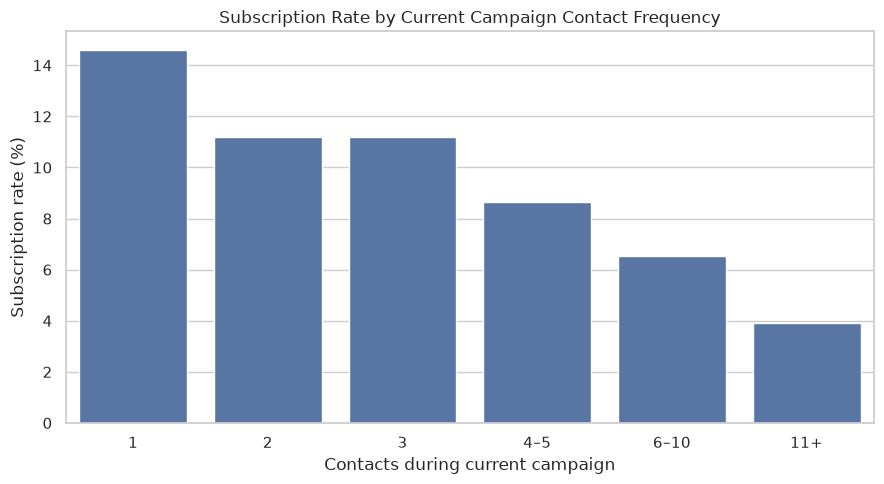

In [12]:
# Create descriptive contact-frequency groups from the original campaign count.
campaign_grouped = df.assign(
    campaign_group=pd.cut(
        df["campaign"],
        bins=[0, 1, 2, 3, 5, 10, float("inf")],
        labels=["1", "2", "3", "4–5", "6–10", "11+"],
    )
)

# Calculate group sizes, subscription counts, and subscription rates.
campaign_summary = (
    campaign_grouped.groupby("campaign_group", observed=False)
                    .agg(
                        customers=("y", "size"),
                        subscriptions=("y", lambda values: values.eq("yes").sum()),
                        subscription_rate=(
                            "y", lambda values: values.eq("yes").mean() * 100
                        ),
                    )
                    .round(2)
)
print("Subscription outcomes by current campaign contact frequency:")
display(campaign_summary)

# Visualize subscription rate by contact-frequency group.
plt.figure(figsize=(9, 5))
ax = sns.barplot(
    data=campaign_summary.reset_index(),
    x="campaign_group",
    y="subscription_rate",
)
ax.set_title("Subscription Rate by Current Campaign Contact Frequency")
ax.set_xlabel("Contacts during current campaign")
ax.set_ylabel("Subscription rate (%)")
plt.tight_layout()
plt.show()

## 6. Prediction-time availability and target leakage

The intended prediction is made before the current campaign call. A feature should only be used if it would be available at that point.

### `duration`: exclude from the primary pre-call model

Call duration is strongly associated with the outcome, but is only known during or after the call. Using it to predict subscription before the call would introduce target leakage and produce an unrealistic evaluation.

Keep `duration` in this notebook for exploratory analysis, but exclude it from the primary pre-call model.

### `campaign`: transform before modeling

The `campaign` feature represents the total number of contacts during the current campaign, including the current contact. Because the intended prediction occurs before the current call, the original value is not directly available at prediction time.

For modeling, derive `contacts_before_current_call` by subtracting one from `campaign`. This represents the number of contacts made before the current call. The original `campaign` feature should not be included as a predictor.

### `pdays`: preserve the sentinel meaning

A value of `-1` means the customer was not previously contacted. It is not an elapsed-day measurement. A modeling workflow can represent this with:
- an indicator for whether the customer was previously contacted; and
- elapsed days since prior contact for customers who were contacted.

The next modeling notebook should create these features without modifying this original EDA dataframe.

In [13]:
# Document call-duration scale; this variable is exploratory only, not a pre-call predictor.
print("Call duration summary (seconds):")
display(df["duration"].describe().to_frame(name="duration_seconds"))

# Quantify how common the pdays sentinel value is.
never_contacted_count = df["pdays"].eq(-1).sum()
never_contacted_rate = df["pdays"].eq(-1).mean() * 100
print(f"Customers never previously contacted: {never_contacted_count:,}")
print(f"Share never previously contacted: {never_contacted_rate:.2f}%")

Call duration summary (seconds):


,duration_seconds
count,45211.000000
mean,258.163080
std,257.527812
min,0.000000
25%,103.000000
50%,180.000000
75%,319.000000
max,4918.000000


Customers never previously contacted: 36,954
Share never previously contacted: 81.74%


## 7. EDA findings and modeling handoff

### Key Findings
#### Target distribution
Only 11.7% of customers subscribed to a term deposit, indicating a substantial class imbalance. Model evaluation should therefore consider precision, recall, F1-score, and precision-recall AUC rather than relying on accuracy alone.

#### Data Quality
The dataset contains no true missing values or exact duplicate rows. However, several categorical features contain explicit `unknown` values. These are particulary common in `poutcome` (36,959 records) and `contact`(13020 records) and should be considered during preprocessing.

#### Customer characteristics
Subscription rates vary across customer categories. Students (28.68%) and retired customers (22.79%) have relatively high subscription rates by job category. Tertiary-educated customers have a 15.01% subscription rate, while single customers have a 14.95% rate. These rates should be considered along side group sizes when evaluating potential marketing opportunities.

#### Previous campaign outcomes
Customers whose previous campaign outcome was successful had a substatially higher subscription rate (64.73%) than customers with previous outcomes of failure (12.61%) or other (16.68%). Customers with an unknown previous outcome had a subscription rate of 9.16%.

#### Current campaign contact frequency
Subscription rates generally declined as the numer of contacts during the current campaign increased. This is an observed association and does not establish that additional contacts cause lower subscription rates.

#### Prediction-time considerations
Call duration is excluded from the primary prediction model because it is only known after the call is ended. The availability of the `campaign` feature also requires review because its original definition includes the current contact. The modeling dataset should only contain information available at the intended prediction time.

### Modeling handoff

For the primary pre-call model:
- Use `y` as the binary target (`no` = 0, `yes` = 1).
- Exclude `duration`.
- Do not use the exploratory `campaign_group` as a modeling feature. Transform the original `campaign` feature into `contacts_before_current_call` by subtracting one, and exclude the original feature.
- Retain `unknown` as an explicit category in the initial modeling baseline.
- Represent prior contact with a separate indicator and elapsed-days feature rather than treating `pdays = -1` as a real elapsed time.
- Split the data into training and test sets before fitting preprocessing transformations.

**Scope:** This notebook is for exploratory analysis. Feature engineering, train/test splitting, preprocessing pipelines, model fitting, and evaluation belong in the modeling notebook so the EDA remains focused and reproducible.